# Deep Learning Practical Exam — Set A

1. ANN — Pima Indians Diabetes binary classification
2. OpenCV — image preprocessing pipeline
3. CNN — CIFAR-10 image classification
4. RNN/LSTM — monthly airline passenger forecasting
5. Transformers — Hugging Face text sentiment classification
6. Comparison, reflection, and GitHub submission checklist


## 0. Setup and imports
Install the packages in `requirements.txt` in your environment. If TensorFlow or Transformers is unavailable, install the requirements and restart the kernel.

In [1]:
import os, time, warnings, json
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

print("Python project setup complete.")
print("Working directory:", os.getcwd())

Python project setup complete.
Working directory: c:\Deep Learning\Practical Test


## Step 1 — ANN: Pima Indians Diabetes Dataset
**Task:** Predict whether a patient has diabetes (binary classification).

The assignment specifies a train/test split, feature scaling, a Sequential ANN, training/validation curves, and Accuracy, Precision, Recall, F1 and Confusion Matrix. The code below uses the local `diabetes.csv` file.

In [2]:
# Load the Pima Indians Diabetes dataset.
# If diabetes.csv is not beside this notebook, try downloading it automatically.
DIABETES_PATH = "diabetes.csv"

if os.path.exists(DIABETES_PATH):
    diabetes = pd.read_csv(DIABETES_PATH)
    print("Loaded local dataset:", DIABETES_PATH)
else:
    dataset_url = (
        "https://raw.githubusercontent.com/"
        "jbrownlee/Datasets/master/"
        "pima-indians-diabetes.data.csv"
    )
    expected_columns = [
        "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
    ]
    try:
        diabetes = pd.read_csv(dataset_url, header=None, names=expected_columns)
        diabetes.to_csv(DIABETES_PATH, index=False)
        print("Downloaded dataset and saved it as:", DIABETES_PATH)
    except Exception as e:
        raise FileNotFoundError(
            "Could not find diabetes.csv or download the dataset. "
            "Download the Pima Indians Diabetes CSV and save it as "
            "'diabetes.csv' in the same folder as this notebook. "
            "Internet connection is required for automatic download."
        ) from e

diabetes.columns = diabetes.columns.str.strip()
print("Dataset shape:", diabetes.shape)
display(diabetes.head())
print("\\nMissing values by column:\\n", diabetes.isna().sum())
print("Columns:", list(diabetes.columns))

Loaded local dataset: diabetes.csv
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


\nMissing values by column:\n Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEED)

# Normalize common target-column naming.
target_candidates = [c for c in diabetes.columns if c.lower() in ("outcome", "target", "diabetes")]
if not target_candidates:
    raise ValueError("Could not find target column. Rename the label column to 'Outcome'.")
target_col = target_candidates[0]
diabetes = diabetes.dropna().copy()
X = diabetes.drop(columns=[target_col]).select_dtypes(include=[np.number])
y = diabetes[target_col].astype(int)
if X.shape[1] == 0:
    raise ValueError("No numeric predictor columns were found.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ann = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="ann_diabetes")
ann.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
ann.summary()

start = time.time()
ann_history = ann.fit(
    X_train_scaled, y_train,
    validation_split=0.20, epochs=50, batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    )],
    verbose=1
)
ann_training_seconds = time.time() - start
ann_probs = ann.predict(X_test_scaled, verbose=0).ravel()
ann_pred = (ann_probs >= 0.5).astype(int)

ann_metrics = {
    "Accuracy": accuracy_score(y_test, ann_pred),
    "Precision": precision_score(y_test, ann_pred, zero_division=0),
    "Recall": recall_score(y_test, ann_pred, zero_division=0),
    "F1": f1_score(y_test, ann_pred, zero_division=0),
    "Training time (seconds)": ann_training_seconds
}
print(pd.Series(ann_metrics).round(4))
print("\\nClassification report:\\n", classification_report(y_test, ann_pred, zero_division=0))
print("Confusion matrix [ [TN, FP], [FN, TP] ]:\\n", confusion_matrix(y_test, ann_pred))

Model: "ann_diabetes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6477 - loss: 0.6555 - val_accuracy: 0.6504 - val_loss: 0.6147
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6599 - loss: 0.6290 - val_accuracy: 0.6585 - val_loss: 0.5933
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6660 - loss: 0.6071 - val_accuracy: 0.6585 - val_loss: 0.5746
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6721 - loss: 0.5883 - val_accuracy: 0.6585 - val_loss: 0.5590
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6762 - loss: 0.5727 - val_accuracy: 0.6423 - val_loss: 0.5458
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6802 - loss: 0.5596 - val_accuracy: 0.6504 - val_loss: 0.5345
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6802 - loss: 0.5483 - val_accuracy: 0.6504 - val_loss: 0.5255
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6925 - loss: 0.5384 - val_accuracy: 0.6829 - val_loss

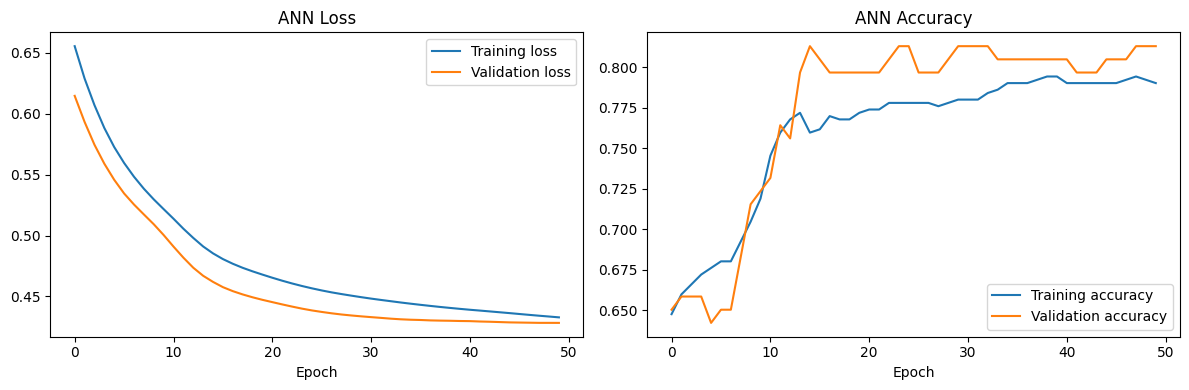

Saved: ann_diabetes_model.h5


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ann_history.history["loss"], label="Training loss")
ax[0].plot(ann_history.history["val_loss"], label="Validation loss")
ax[0].set_title("ANN Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(ann_history.history["accuracy"], label="Training accuracy")
ax[1].plot(ann_history.history["val_accuracy"], label="Validation accuracy")
ax[1].set_title("ANN Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

ann.save("ann_diabetes_model.h5")
print("Saved: ann_diabetes_model.h5")


### Step 1 — Answer / reflection
- **Why scale features?** The medical measurements have different units and ranges. Standardization helps gradient-based optimization train more consistently.
- **Why sigmoid?** The target is binary, and sigmoid outputs a value between 0 and 1 that can be interpreted as the estimated positive-class probability.
- **Why use recall?** Missing a patient who has diabetes can be costly, so recall is important alongside precision and F1. Threshold selection should be based on the intended use and validated clinically.
- **Overfitting check:** If training loss keeps falling while validation loss rises, the model may be overfitting. Early stopping monitors validation loss and restores the best weights.
- The exact scores depend on the dataset file, data cleaning, split and random seed; use the values printed by your run rather than inventing results.

## Step 2 — OpenCV: Image Preprocessing Pipeline
**Task:** Load five images, convert to grayscale, resize, blur, detect edges, and draw a green bounding rectangle. This is a preprocessing demonstration, not a trained detection model.

In [5]:
import cv2
import matplotlib.pyplot as plt

from pathlib import Path

# Put 5 image files in a folder named images/ (JPG, JPEG or PNG).
image_dir = Path("images")
image_paths = []
if image_dir.exists():
    for pattern in ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"):
        image_paths.extend(image_dir.glob(pattern))
image_paths = sorted(set(image_paths))[:5]

if len(image_paths) < 5:
    print(f"Found {len(image_paths)} image(s). Add at least 5 images to '{image_dir}/' to complete this task.")
else:
    print("Using images:", [p.name for p in image_paths])

Using images: ['41586_2015_Article_BF528452a_Figg_HTML.jpg', 'images (2).jpg', 'images (3).jpg', 'images (4).jpg', 'images (5).jpg']


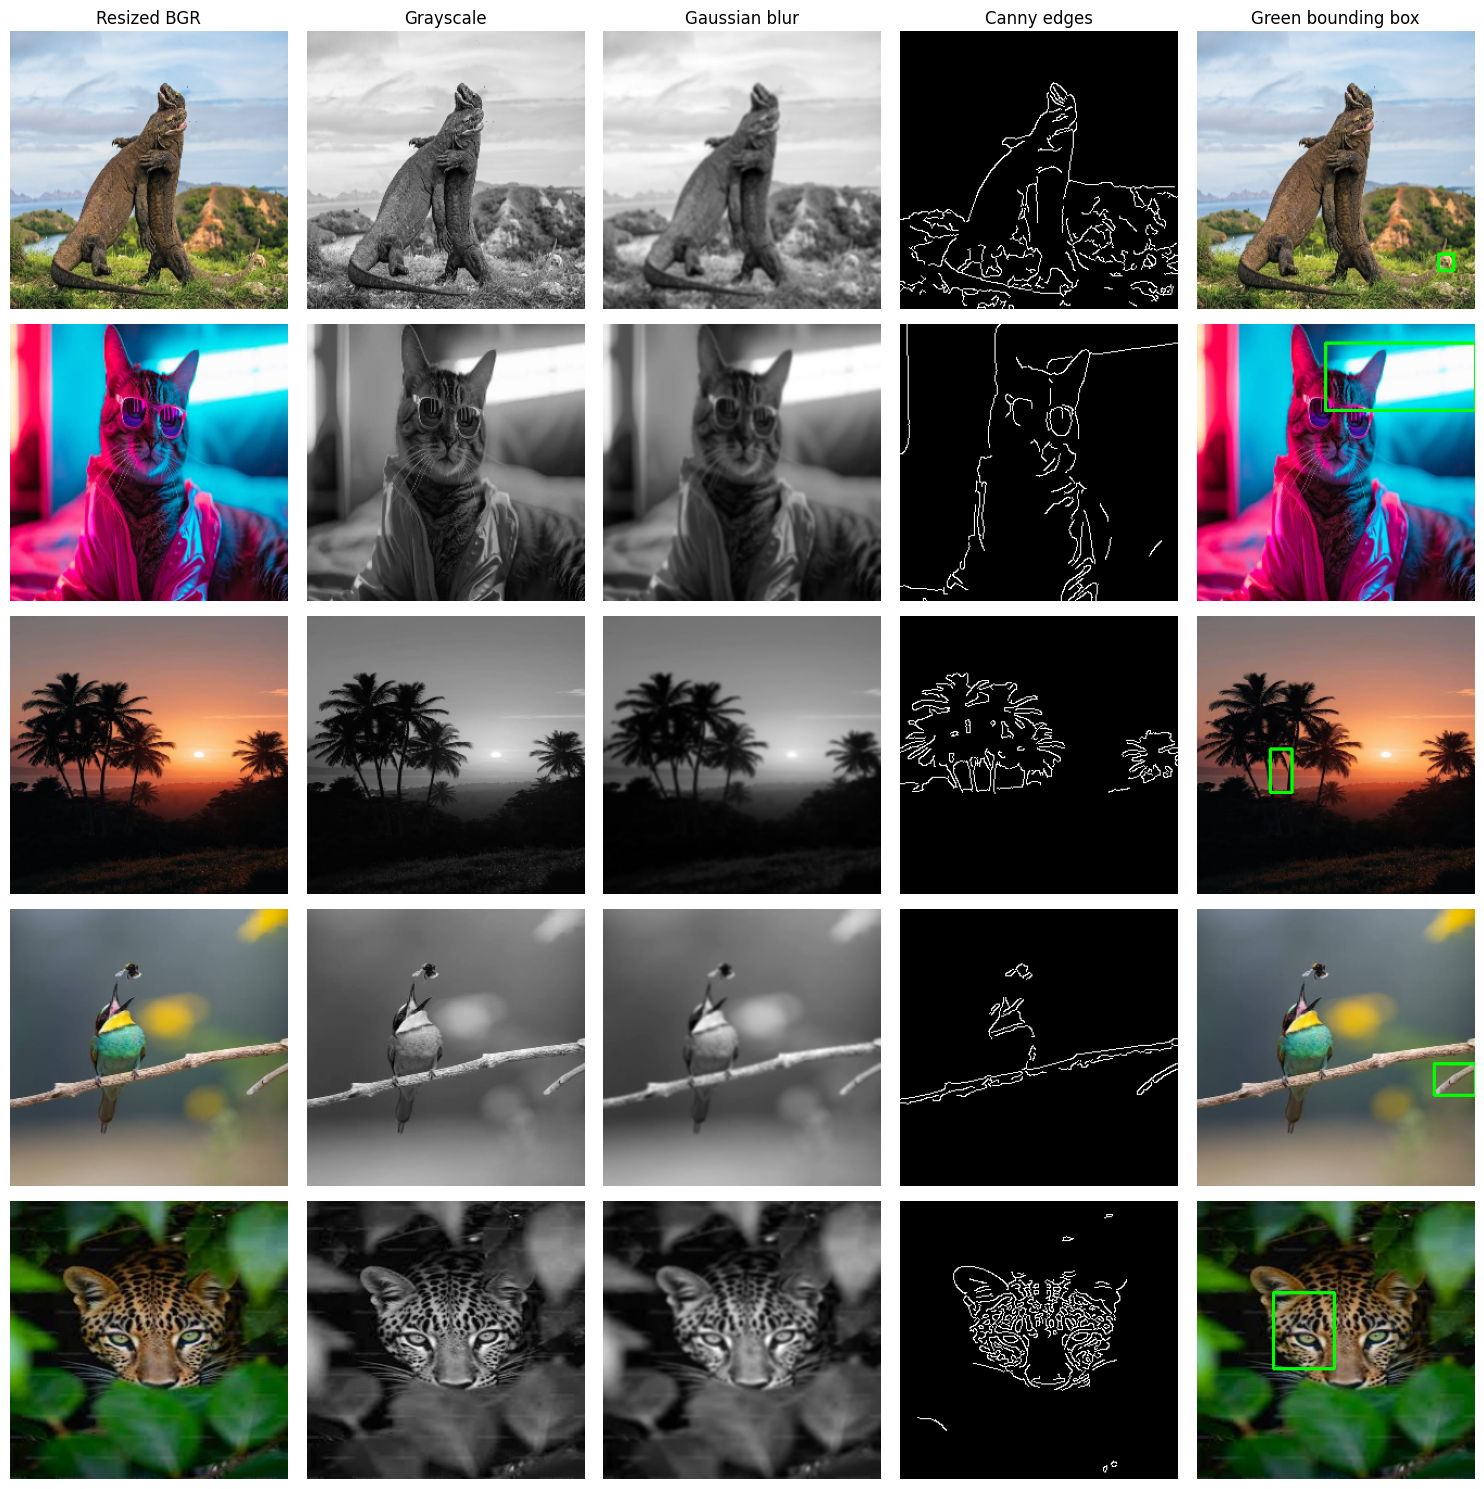

Saved processed images in opencv_outputs/


In [6]:
def preprocess_image(path, size=(256, 256)):
    image_bgr = cv2.imread(str(path))
    if image_bgr is None:
        raise ValueError(f"OpenCV could not read {path}")
    resized = cv2.resize(image_bgr, size)
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 100, 200)

    # A contour-based bounding box for the largest detected edge contour.
    output = resized.copy()
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest)
        cv2.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 2)
    return resized, gray, blurred, edges, output

opencv_outputs = []
if len(image_paths) >= 5:
    for p in image_paths:
        op = preprocess_image(p)
        opencv_outputs.append((p.name, op))
    fig, axes = plt.subplots(5, 5, figsize=(15, 15))
    titles = ["Resized BGR", "Grayscale", "Gaussian blur", "Canny edges", "Green bounding box"]
    for r, (name, outputs) in enumerate(opencv_outputs):
        for c, arr in enumerate(outputs):
            if c == 0 or c == 4:
                axes[r, c].imshow(cv2.cvtColor(arr, cv2.COLOR_BGR2RGB))
            else:
                axes[r, c].imshow(arr, cmap="gray")
            axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(titles[c])
        axes[r, 0].set_ylabel(name)
    plt.tight_layout(); plt.show()

    output_dir = Path("opencv_outputs")
    output_dir.mkdir(exist_ok=True)
    for name, outputs in opencv_outputs:
        cv2.imwrite(str(output_dir / f"processed_{name}"), outputs[-1])
    print("Saved processed images in opencv_outputs/")


### Step 2 — Answer / reflection
- **Grayscale** reduces each pixel to intensity, which is often sufficient for edge detection.
- **Gaussian blur** reduces small noise before edge detection.
- **Canny** detects strong intensity changes; its result depends on the chosen thresholds.
- **Bounding-box limitation:** The largest contour is not guaranteed to be the semantic object. For reliable object detection, use a trained detector and evaluate its predictions.
- OpenCV uses BGR image order when loading and saving; Matplotlib display requires conversion to RGB for correct colors.

## Step 3 — CNN: CIFAR-10 Image Classification
**Task:** Train a small CNN on CIFAR-10 (10 classes). To keep CPU execution manageable, this notebook uses a configurable subset. Increase the sample sizes/epochs if your machine has sufficient compute.

In [11]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

(x_train_all, y_train_all), (x_test_all, y_test_all) = cifar10.load_data()
# Smaller subset for a practical exam; increase these values for better results.
TRAIN_SAMPLES = min(20000, len(x_train_all))
TEST_SAMPLES = min(4000, len(x_test_all))
x_train_cnn = x_train_all[:TRAIN_SAMPLES].astype("float32") / 255.0
x_test_cnn = x_test_all[:TEST_SAMPLES].astype("float32") / 255.0
y_train_cnn = to_categorical(y_train_all[:TRAIN_SAMPLES], 10)
y_test_cnn = to_categorical(y_test_all[:TEST_SAMPLES], 10)
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
print("Train:", x_train_cnn.shape, "Test:", x_test_cnn.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4826s 28us/step
Train: (20000, 32, 32, 3) Test: (4000, 32, 32, 3)


In [12]:
cnn = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(10, activation="softmax")
], name="cnn_cifar10")
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
cnn.summary()
start = time.time()
cnn_history = cnn.fit(
    x_train_cnn, y_train_cnn, validation_split=0.10,
    epochs=10, batch_size=64,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
    verbose=1
)
cnn_training_seconds = time.time() - start
cnn_test_loss, cnn_test_acc = cnn.evaluate(x_test_cnn, y_test_cnn, verbose=0)
print({"Test loss": float(cnn_test_loss), "Test accuracy": float(cnn_test_acc),
       "Training time (seconds)": round(cnn_training_seconds, 2)})
cnn.save("cnn_cifar10_model.h5")
print("Saved: cnn_cifar10_model.h5")

Model: "cnn_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.2678 - loss: 1.9763 - val_accuracy: 0.4130 - val_loss: 1.6686
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.3865 - loss: 1.6697 - val_accuracy: 0.4715 - val_loss: 1.4744
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.4508 - loss: 1.5106 - val_accuracy: 0.5195 - val_loss: 1.3542
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.4947 - loss: 1.4009 - val_accuracy: 0.5410 - val_loss: 1.3251
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.5247 - loss: 1.3138 - val_accuracy: 0.5580 - val_loss: 1.2987
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5612 - loss: 1.2236 - val_accuracy: 0.5865 - val_loss: 1.1798
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5829 - loss: 1.1666 - val_accuracy: 0.5860 - val_loss: 1.1899
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.6037 - loss: 1.0959 - val_accu

{'Test loss': 1.049277663230896, 'Test accuracy': 0.6315000057220459, 'Training time (seconds)': 47.8}
Saved: cnn_cifar10_model.h5


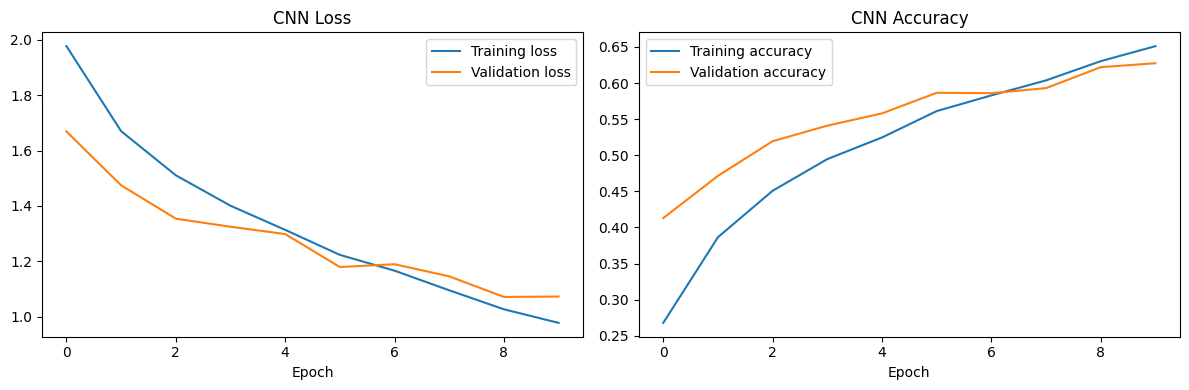

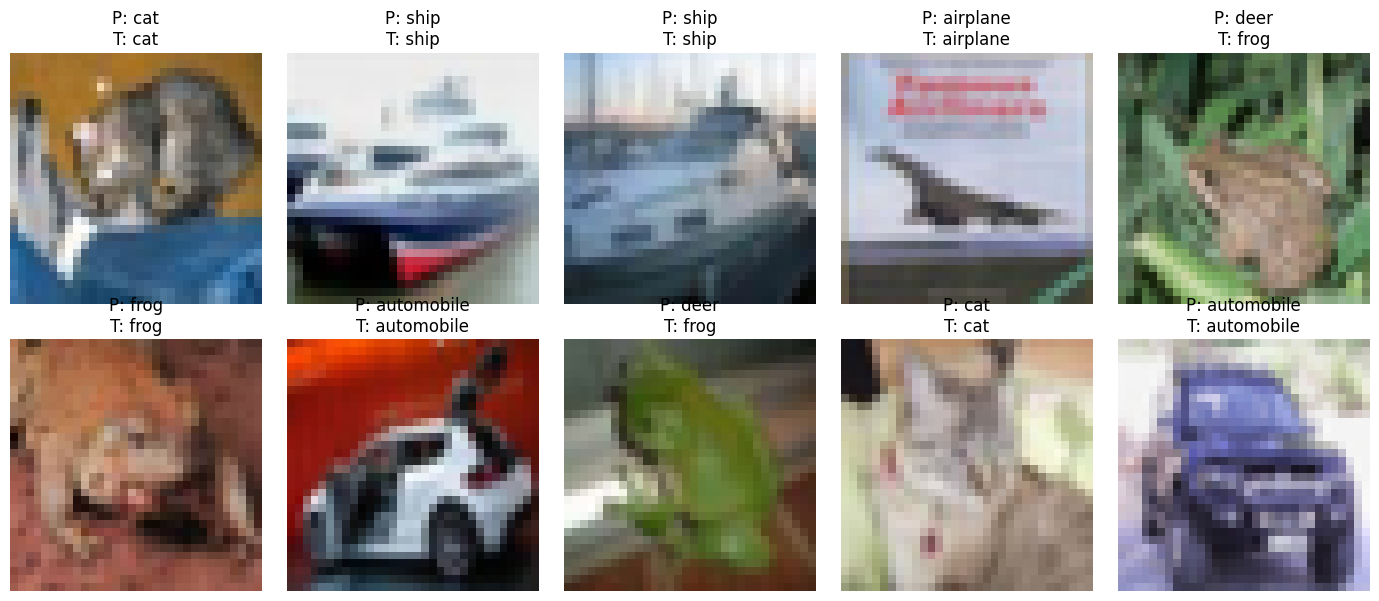

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cnn_history.history["loss"], label="Training loss")
ax[0].plot(cnn_history.history["val_loss"], label="Validation loss")
ax[0].set_title("CNN Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(cnn_history.history["accuracy"], label="Training accuracy")
ax[1].plot(cnn_history.history["val_accuracy"], label="Validation accuracy")
ax[1].set_title("CNN Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

pred_prob = cnn.predict(x_test_cnn[:10], verbose=0)
pred_labels = np.argmax(pred_prob, axis=1)
true_labels = np.argmax(y_test_cnn[:10], axis=1)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test_cnn[i])
    ax.set_title(f"P: {class_names[pred_labels[i]]}\nT: {class_names[true_labels[i]]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Step 3 — Answer / reflection
- **Convolution layers** learn local visual patterns such as edges, textures and parts.
- **Max pooling** reduces spatial dimensions and computation.
- **Softmax** converts the ten output scores into class probabilities.
- **Why is CIFAR-10 difficult?** Images are small (32×32), and classes such as cats/dogs or automobiles/trucks can look similar.
- **Data augmentation** (random flips/crops) can improve generalization, but it increases training complexity. Dropout and early stopping are also useful regularization methods.
- Accuracy depends on subset size, epochs, hardware and package versions; report the score from your run.

## Step 4 — RNN/LSTM: Monthly Airline Passenger Forecasting
The brief requests a time-series model, actual-vs-predicted plot, RMSE and a future forecast. This section tries to load a public CSV; if internet access is unavailable, place an `AirPassengers.csv` file beside the notebook with `Month` and `Passengers` columns.

,Month,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


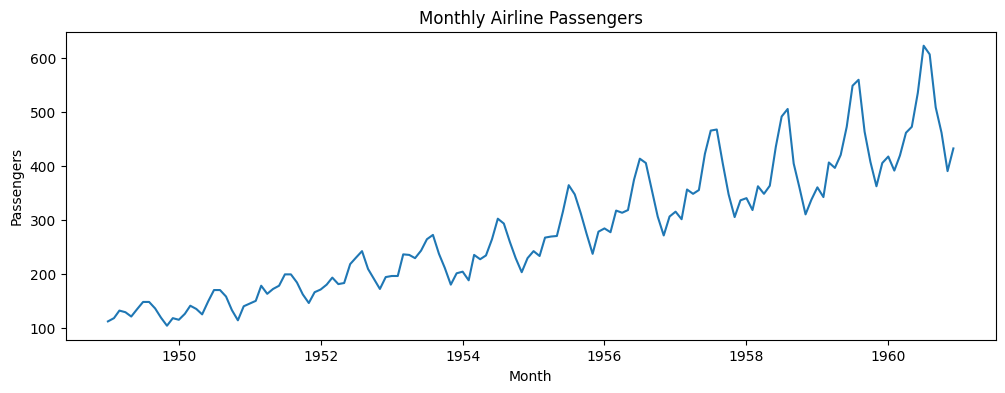

In [14]:
from pathlib import Path

airline = None
local_airline = Path("AirPassengers.csv")
if local_airline.exists():
    airline = pd.read_csv(local_airline)
else:
    urls = [
        "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv",
        "https://raw.githubusercontent.com/selva86/datasets/master/AirPassengers.csv"
    ]
    for url in urls:
        try:
            airline = pd.read_csv(url)
            break
        except Exception as e:
            print("Could not load", url, "—", str(e)[:120])

if airline is None:
    raise FileNotFoundError("Download an airline passengers CSV and save it as AirPassengers.csv beside this notebook.")
airline.columns = [c.strip() for c in airline.columns]
# Support common column-name variants.
date_col = next((c for c in airline.columns if c.lower() in ("month", "date", "time")), airline.columns[0])
value_col = next((c for c in airline.columns if "passenger" in c.lower()), airline.columns[-1])
airline[date_col] = pd.to_datetime(airline[date_col], errors="coerce")
airline[value_col] = pd.to_numeric(airline[value_col].astype(str).str.replace(",", ""), errors="coerce")
airline = airline.dropna(subset=[date_col, value_col]).sort_values(date_col)
airline = airline[[date_col, value_col]].rename(columns={date_col: "Month", value_col: "Passengers"})
display(airline.head())
plt.figure(figsize=(12, 4)); plt.plot(airline["Month"], airline["Passengers"])
plt.title("Monthly Airline Passengers"); plt.xlabel("Month"); plt.ylabel("Passengers"); plt.show()

{'Test RMSE (passengers)': 63.351, 'Training time (seconds)': 14.35}


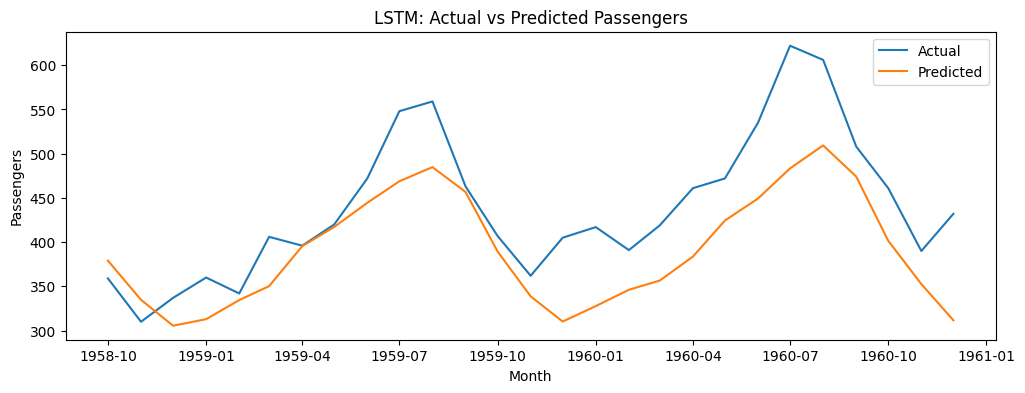

,Month,Forecast_Passengers
0,1961-01-01,320.7
1,1961-02-01,284.2
2,1961-03-01,278.0
3,1961-04-01,299.7
4,1961-05-01,343.0
5,1961-06-01,402.5
6,1961-07-01,462.8
7,1961-08-01,500.8
8,1961-09-01,503.9
9,1961-10-01,480.2


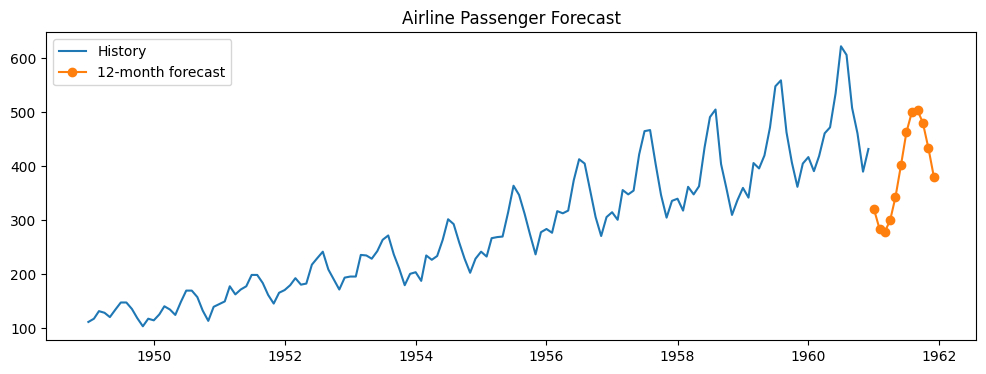

Saved: lstm_airline_model.h5 and airline_12_month_forecast.csv


In [15]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

values = airline["Passengers"].to_numpy(dtype="float32").reshape(-1, 1)
scaler_ts = MinMaxScaler()
scaled = scaler_ts.fit_transform(values)

def make_sequences(data, lookback=12):
    X_seq, y_seq = [], []
    for i in range(lookback, len(data)):
        X_seq.append(data[i-lookback:i, 0])
        y_seq.append(data[i, 0])
    return np.array(X_seq), np.array(y_seq)

LOOKBACK = 12
X_seq, y_seq = make_sequences(scaled, LOOKBACK)
split = int(len(X_seq) * 0.80)
X_train_ts, X_test_ts = X_seq[:split], X_seq[split:]
y_train_ts, y_test_ts = y_seq[:split], y_seq[split:]
X_train_ts = X_train_ts.reshape((-1, LOOKBACK, 1))
X_test_ts = X_test_ts.reshape((-1, LOOKBACK, 1))

lstm = keras.Sequential([
    layers.Input(shape=(LOOKBACK, 1)),
    layers.LSTM(32),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
], name="lstm_airline")
lstm.compile(optimizer="adam", loss="mse")
start = time.time()
lstm_history = lstm.fit(
    X_train_ts, y_train_ts, epochs=100, batch_size=16,
    validation_split=0.15,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
    verbose=0
)
lstm_training_seconds = time.time() - start
test_pred_scaled = lstm.predict(X_test_ts, verbose=0)
test_pred = scaler_ts.inverse_transform(test_pred_scaled)
test_actual = scaler_ts.inverse_transform(y_test_ts.reshape(-1, 1))
rmse = float(np.sqrt(mean_squared_error(test_actual, test_pred)))
print({"Test RMSE (passengers)": round(rmse, 3), "Training time (seconds)": round(lstm_training_seconds, 2)})

test_dates = airline["Month"].iloc[LOOKBACK + split:]
plt.figure(figsize=(12, 4))
plt.plot(test_dates, test_actual.ravel(), label="Actual")
plt.plot(test_dates, test_pred.ravel(), label="Predicted")
plt.title("LSTM: Actual vs Predicted Passengers"); plt.xlabel("Month"); plt.ylabel("Passengers")
plt.legend(); plt.show()

# Forecast the next 12 months recursively.
window = scaled[-LOOKBACK:].reshape(1, LOOKBACK, 1)
future_scaled = []
for _ in range(12):
    nxt = float(lstm.predict(window, verbose=0)[0, 0])
    future_scaled.append(nxt)
    window = np.concatenate([window[:, 1:, :], np.array(nxt).reshape(1, 1, 1)], axis=1)
future_values = scaler_ts.inverse_transform(np.array(future_scaled).reshape(-1, 1)).ravel()
future_dates = pd.date_range(airline["Month"].iloc[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
forecast_df = pd.DataFrame({"Month": future_dates, "Forecast_Passengers": np.round(future_values, 1)})
display(forecast_df)
plt.figure(figsize=(12, 4))
plt.plot(airline["Month"], airline["Passengers"], label="History")
plt.plot(forecast_df["Month"], forecast_df["Forecast_Passengers"], marker="o", label="12-month forecast")
plt.legend(); plt.title("Airline Passenger Forecast"); plt.show()
lstm.save("lstm_airline_model.h5")
forecast_df.to_csv("airline_12_month_forecast.csv", index=False)
print("Saved: lstm_airline_model.h5 and airline_12_month_forecast.csv")

### Step 4 — Answer / reflection
- **Why LSTM?** LSTM gates help retain useful information over sequences and can learn temporal dependencies.
- **Why use a chronological split?** Randomly shuffling time-series data leaks future information into training. The test segment should occur after the training segment.
- **Why RMSE?** It measures typical prediction error in the original passenger-count units and penalizes large errors more strongly.
- **Caution:** This dataset has a strong trend and seasonal pattern. Recursive forecasts accumulate errors; the forecast is an educational demonstration, not an operational planning guarantee.

## Step 5 — Transformers: Text Classification with Hugging Face
The brief describes using a pretrained sentiment-analysis pipeline on 25 sentences, then displaying labels/scores and reflecting on bias and limitations. A pipeline downloads model files on first use and needs internet access the first time.

In [16]:
# If needed, install: pip install transformers torch
from transformers import pipeline

sentences = [
    "This movie was wonderful and deeply moving.",
    "The food was cold and the service was terrible.",
    "I enjoyed the performance and would watch it again.",
    "The product broke after one day.",
    "The story was predictable but the acting was excellent.",
    "I am disappointed with this purchase.",
    "A brilliant experience from beginning to end.",
    "The delivery arrived late and the package was damaged.",
    "It was fine, nothing special.",
    "The soundtrack is beautiful.",
    "I would not recommend this restaurant.",
    "Customer support solved my problem quickly.",
    "The interface is confusing and frustrating.",
    "I love the design and the quality.",
    "The ending made no sense.",
    "Good value for the price.",
    "The room was dirty and noisy.",
    "I had a fantastic time.",
    "The book was boring and repetitive.",
    "The staff were friendly and helpful.",
    "The instructions were unclear.",
    "The update fixed several annoying bugs.",
    "I expected more for the money.",
    "The experience exceeded my expectations.",
    "The film was neither good nor bad."
]
sentiment_pipe = pipeline("sentiment-analysis")
sentiment_results = sentiment_pipe(sentences, truncation=True)
sentiment_df = pd.DataFrame({
    "Sentence": sentences,
    "Predicted label": [r["label"] for r in sentiment_results],
    "Confidence score": [round(float(r["score"]), 4) for r in sentiment_results]
})
display(sentiment_df)
sentiment_df.to_csv("transformer_sentiment_results.csv", index=False)
print("Saved: transformer_sentiment_results.csv")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1120.81it/s]


,Sentence,Predicted label,Confidence score
0,This movie was wonderful and deeply moving.,POSITIVE,0.9999
1,The food was cold and the service was terrible.,NEGATIVE,0.9997
2,I enjoyed the performance and would watch it a...,POSITIVE,0.9999
3,The product broke after one day.,NEGATIVE,0.9988
4,The story was predictable but the acting was e...,POSITIVE,0.9998
5,I am disappointed with this purchase.,NEGATIVE,0.9998
6,A brilliant experience from beginning to end.,POSITIVE,0.9999
7,The delivery arrived late and the package was ...,NEGATIVE,0.9997
8,"It was fine, nothing special.",NEGATIVE,0.9576
9,The soundtrack is beautiful.,POSITIVE,0.9999


Saved: transformer_sentiment_results.csv


### Step 5 — Answer / reflection
- **What is a Transformer?** A neural architecture that uses attention to model relationships between tokens in a sequence.
- **What does the pipeline return?** A predicted label and a confidence-like score for the selected pretrained model.
- **Does a high score prove the prediction is correct?** No. The score is model confidence, not a guarantee of correctness.
- **Bias and limitations:** The model may misread sarcasm, slang, cultural context, mixed sentiment or domain-specific language. Its training data may not represent all groups or languages.
- **Fine-tuning vs pipeline:** A pretrained pipeline is quick to demonstrate. Fine-tuning on representative, labeled domain data can improve task fit but requires more data, compute and evaluation.

## Step 6 — Comparison, reflection and submission
Run this cell after the relevant steps have completed. The table records metrics only for tasks that have run in this session.

In [17]:
comparison_rows = []
if "ann_metrics" in globals():
    comparison_rows.append({
        "Step / model": "ANN — Diabetes",
        "Task": "Binary classification",
        "Dataset": "Pima Indians Diabetes (local CSV)",
        "Key metric": f"Accuracy={ann_metrics['Accuracy']:.3f}; F1={ann_metrics['F1']:.3f}",
        "Training time (s)": round(ann_metrics["Training time (seconds)"], 2)
    })
if "cnn_test_acc" in globals():
    comparison_rows.append({
        "Step / model": "CNN — CIFAR-10",
        "Task": "10-class image classification",
        "Dataset": "CIFAR-10",
        "Key metric": f"Test accuracy={cnn_test_acc:.3f}",
        "Training time (s)": round(cnn_training_seconds, 2)
    })
if "rmse" in globals():
    comparison_rows.append({
        "Step / model": "LSTM — Airline passengers",
        "Task": "Time-series forecasting",
        "Dataset": "Monthly airline passengers",
        "Key metric": f"RMSE={rmse:.2f} passengers",
        "Training time (s)": round(lstm_training_seconds, 2)
    })
if "sentiment_df" in globals():
    comparison_rows.append({
        "Step / model": "Transformer — Sentiment",
        "Task": "Text sentiment classification",
        "Dataset": "25 example sentences",
        "Key metric": f"{len(sentiment_df)} sentences classified",
        "Training time (s)": "Pretrained inference; no training"
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
comparison_df.to_csv("comparison_summary.csv", index=False)
print("Saved: comparison_summary.csv")

,Step / model,Task,Dataset,Key metric,Training time (s)
0,ANN — Diabetes,Binary classification,Pima Indians Diabetes (local CSV),Accuracy=0.766; F1=0.654,9.18
1,CNN — CIFAR-10,10-class image classification,CIFAR-10,Test accuracy=0.632,47.8
2,LSTM — Airline passengers,Time-series forecasting,Monthly airline passengers,RMSE=63.35 passengers,14.35
3,Transformer — Sentiment,Text sentiment classification,25 example sentences,25 sentences classified,Pretrained inference; no training


Saved: comparison_summary.csv
